# Tokenização: do texto aos IDs

A rede não lê letras: ela lê **números inteiros**. Cada número é o índice de uma linha na tabela de
embeddings, e o vetor dessa linha é o que entra no Transformer. Tokenizar é decidir **em que pedaços
o texto é cortado** antes de virar número.

Há três escolhas possíveis:

| Corte | Vocabulário | Sequência | Problema |
|---|---|---|---|
| Por caractere | ~175 símbolos | muito longa (~120 posições por resenha) | o modelo gasta contexto e cálculo soletrando |
| Por palavra | ~29 mil palavras (só as que aparecem 2+ vezes) | curta | palavra nova vira `<unk>` e a camada de saída fica enorme |
| **BPE (subpalavras)** | **4.000 tokens** | ~1,5 token por palavra (pontuação inclusa) | — é o meio-termo |

Este notebook mostra o algoritmo BPE passo a passo, com o código didático de
`src/nano_review/tokenization/bpe_demo.py`. Depois mostra o tokenizador do projeto, treinado com a
biblioteca `tokenizers` **só no conjunto de treino** (`models/tokenizer.json`, gerado pelo
`dvc repro`). No fim, ele mede o comprimento das resenhas em tokens, que é o dado para escolher o
contexto máximo do modelo (`block_size`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from tokenizers import Tokenizer

from nano_review.tokenization.bpe import SPECIAL_TOKENS, decode, encode_review
from nano_review.tokenization.bpe_demo import (
    apply_merges,
    count_pairs,
    merge_pair,
    split_words,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Mesmo padrão visual da EDA: uma cor para série única.
BLUE = "#2a78d6"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "font.size": 10,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)

## 1. O algoritmo BPE à mão

Um corpus de brinquedo, com frases inventadas no estilo das resenhas. Cada palavra começa quebrada em
caracteres, com "▁" marcando o início da palavra. A cada passo, o par de símbolos vizinhos **mais
frequente** vira um símbolo só.

In [2]:
corpus = [
    "recomendo muito bom",
    "muito bom recomendo",
    "bom produto recomendo",
    "produto bom",
    "não recomendo produto ruim",
]
words = split_words(corpus)
print("palavras iniciais:", {" ".join(w): n for w, n in words.items()})

steps = []
for step in range(1, 13):
    pairs = count_pairs(words)
    best = min(pairs, key=lambda pair: (-pairs[pair], pair))  # mesmo critério de train_bpe
    steps.append(
        {"passo": step, "par fundido": f"{best[0]} + {best[1]}", "frequência": pairs[best]}
    )
    words = merge_pair(words, best)
pd.DataFrame(steps).set_index("passo")

palavras iniciais: {'▁ r e c o m e n d o': 4, '▁ m u i t o': 2, '▁ b o m': 4, '▁ p r o d u t o': 3, '▁ n ã o': 1, '▁ r u i m': 1}


,par fundido,frequência
passo,,
1,o + m,8
2,t + o,5
3,▁ + r,5
4,b + om,4
5,c + om,4
6,com + e,4
7,come + n,4
8,comen + d,4
9,comend + o,4


In [3]:
merges = [tuple(row["par fundido"].split(" + ")) for row in steps]
for word in ["recomendo", "bom", "produto", "bonito", "recomendação"]:
    print(f"{word:>14} -> {apply_merges(word, merges)}")

     recomendo -> ['▁recomendo']
           bom -> ['▁bom']
       produto -> ['▁', 'p', 'r', 'o', 'd', 'u', 'to']
        bonito -> ['▁', 'b', 'o', 'n', 'i', 'to']
  recomendação -> ['▁r', 'e', 'comend', 'a', 'ç', 'ã', 'o']


**O que observar**

- As fusões começam pelo par mais frequente ("o + m", que aparece em "bom" e em "recomendo") e
  vão crescendo até virar palavras inteiras: "▁bom" fica pronto no passo 11, e "▁recomendo" no 12.
- Com só 12 fusões, "produto" ainda está quebrado. O tokenizador real tem 4.000 tokens no
  vocabulário, e sobra espaço para as palavras comuns ficarem inteiras.
- "bonito" e "recomendação" nunca apareceram no corpus, mas **não viram desconhecidas**: o BPE usa
  os pedaços que servem ("to", "comend") e deixa o resto em caracteres. É por isso que o
  tokenizador do projeto quase não produz `<unk>`.
- A ordem das fusões é o "modelo" do tokenizador. Para tokenizar um texto novo, ele repete as fusões
  na mesma ordem do treino.

## 2. O tokenizador do projeto

Treinado com a biblioteca `tokenizers` no `train.parquet`, com 4.000 tokens no vocabulário
(`params.yaml`). Os 9 primeiros IDs são os tokens especiais, sempre nos mesmos números.

In [4]:
tokenizer = Tokenizer.from_file(str(ROOT / "models" / "tokenizer.json"))
print("tamanho do vocabulário:", tokenizer.get_vocab_size())
pd.DataFrame({"token": SPECIAL_TOKENS, "id": [tokenizer.token_to_id(t) for t in SPECIAL_TOKENS]})

tamanho do vocabulário: 4000


,token,id
0,<pad>,0
1,<bos>,1
2,<eos>,2
3,<unk>,3
4,<nota_1>,4
5,<nota_2>,5
6,<nota_3>,6
7,<nota_4>,7
8,<nota_5>,8


In [5]:
examples = [
    "Produto muito bom, chegou antes do prazo. Recomendo!",
    "Não recomendo, veio com defeito e a troca demorou.",
    "O liquidificador é potente, mas faz muito barulho.",
    "Superou minhas expectativas, custo-benefício excelente.",
]
for text in examples:
    print(text)
    print("   ", tokenizer.encode(text).tokens)

Produto muito bom, chegou antes do prazo. Recomendo!
    ['▁Produto', '▁muito', '▁bom', ',', '▁chegou', '▁antes', '▁do', '▁prazo', '.', '▁Recomendo', '!']
Não recomendo, veio com defeito e a troca demorou.
    ['▁Não', '▁recomendo', ',', '▁veio', '▁com', '▁defeito', '▁e', '▁a', '▁troca', '▁demorou', '.']
O liquidificador é potente, mas faz muito barulho.
    ['▁O', '▁liquidificador', '▁é', '▁potente', ',', '▁mas', '▁faz', '▁muito', '▁barulho', '.']
Superou minhas expectativas, custo-benefício excelente.
    ['▁Superou', '▁minhas', '▁expectativas', ',', '▁custo', '-', 'benefício', '▁excelente', '.']


**O que observar**

- Palavras comuns em resenha ("▁Produto", "▁muito", "▁Recomendo") e até "▁liquidificador" são um
  token só. Palavras raras seriam quebradas em pedaços que se repetem em outras palavras.
- **A pontuação é um token separado** (",", ".", "!"). Isso foi um achado desta sub-etapa. A
  primeira versão do tokenizador usava só o `Metaspace` e produzia "▁bom," e "▁prazo." como tokens
  próprios: o vocabulário gastava três tokens para "recomendo", "recomendo," e "recomendo.". Com o
  pré-tokenizador `Punctuation` depois do `Metaspace`, a pontuação se separa e o texto volta exato.
- "custo-benefício" quebra no hífen, que também é pontuação.
- Caixa e acento ficam, como decidido na EDA: "▁Não" e "▁não" são tokens diferentes.

## 3. Da resenha ao tensor

O caminho que o DataLoader vai fazer, na seção a seguir com uma resenha só: texto e nota viram a
sequência `<bos> <nota_k> ... <eos>`, que vira uma lista de IDs. Esse é o formato do baseline de
n-gramas também: o token de nota no começo é o **condicionamento**.

In [6]:
ids = encode_review(tokenizer, "Chegou rápido, recomendo.", rating=5)
tokens = [tokenizer.id_to_token(i) for i in ids]
print("IDs:   ", ids)
print("tokens:", tokens)
print("volta: ", decode(tokenizer, ids))

IDs:    [1, 8, 691, 518, 20, 336, 22, 2]
tokens: ['<bos>', '<nota_5>', '▁Chegou', '▁rápido', ',', '▁recomendo', '.', '<eos>']
volta:  Chegou rápido, recomendo.


## 4. Quantos tokens tem uma resenha?

O Transformer tem um contexto máximo (`block_size`): o número de posições que ele enxerga de uma
vez. O custo da atenção cresce com o **quadrado** desse número, então um contexto maior que o
necessário custa caro em CPU. A distribuição abaixo mede o comprimento das resenhas de treino em
tokens, já com `<bos>`, `<nota_k>` e `<eos>`.

In [7]:
metrics = json.loads((ROOT / "reports" / "metrics" / "tokenizer.json").read_text())
summary = pd.DataFrame({name: metrics[name]["sequence_length"] for name in ("train", "validation")})
print("tokens por palavra (treino):", metrics["train"]["tokens_per_word"])
print("taxa de <unk> (validação):", metrics["validation"]["unk_rate"])
summary

tokens por palavra (treino): 1.503
taxa de <unk> (validação): 2e-06


,train,validation
p50,26.0000,26.0000
p90,71.0000,73.0000
p95,96.0000,99.0000
p99,178.0000,178.8400
max,1537.0000,1014.0000
fraction_over_64,0.1201,0.1261
fraction_over_128,0.0244,0.0250
fraction_over_256,0.0033,0.0033


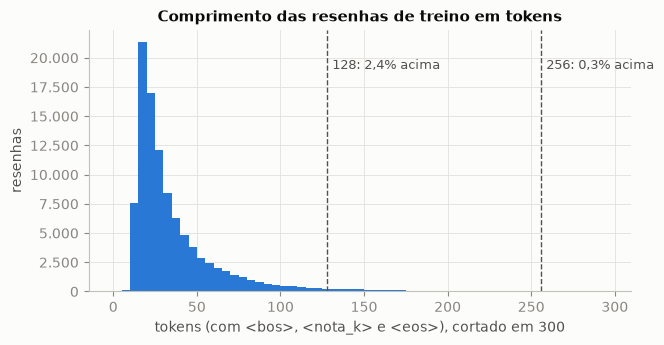

In [8]:
train = pd.read_parquet(ROOT / "data" / "curated" / "train.parquet", columns=["review_text"])
lengths = [len(e.ids) + 3 for e in tokenizer.encode_batch(train["review_text"].tolist())]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(lengths, bins=range(0, 300, 5), color=BLUE)
for block in (128, 256):
    ax.axvline(block, color="#52514e", linewidth=1, linestyle="--")
    share = 100 * sum(n > block for n in lengths) / len(lengths)
    ax.text(
        block + 3,
        ax.get_ylim()[1] * 0.85,
        f"{block}: {share:.1f}% acima".replace(".", ","),
        color="#52514e",
        fontsize=9,
    )
ax.set_title("Comprimento das resenhas de treino em tokens")
ax.set_xlabel("tokens (com <bos>, <nota_k> e <eos>), cortado em 300")
ax.set_ylabel("resenhas")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
fig.savefig(FIG_DIR / "tokens_length.png")
plt.show()

**O que os números dizem**

- Uma palavra vira em média **1,5 token**, contando a pontuação. A resenha mediana tem ~26 tokens,
  e 95% delas têm até ~96.
- **2,4%** das resenhas de treino passam de 128 tokens, e só **0,33%** passam de 256. O máximo
  (~1.500) vem de sequências enormes de pontuação ("!!!!!!…"), em que cada sinal é um token.
- A taxa de `<unk>` na validação é praticamente zero: o BPE cobre palavras que nunca viu.

**Para a decisão do `block_size`** (tomada pelo aluno ao fim da sub-etapa 2.1):

- **128** cobre 97,6% das resenhas e mantém a atenção barata: 128² = 16 mil pares por camada.
- **256** cobre 99,7%, mas custa 4 vezes mais memória na atenção quando o lote tem uma resenha longa.
  O padding dinâmico só alonga o lote quando uma resenha longa aparece nele.
- O charter define o produto como gerador de **resenhas curtas**, e todo exemplo de treino precisa
  terminar em `<eos>` para o modelo aprender a parar.